In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

DATASET_PATH = "/kaggle/input/datasets/arshjaved/news-articles/articles.parquet"
df = pd.read_parquet(DATASET_PATH)

print(f"Dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

Dataset loaded: 63,267 rows x 24 columns
Memory usage: 696.7 MB


In [2]:
print("=" * 60)
print("COLUMN TYPES & NON-NULL COUNTS")
print("=" * 60)
df.info(show_counts=True)

print("\n")
print("=" * 60)
print("FIRST 3 ROWS")
print("=" * 60)
df.head(3)

COLUMN TYPES & NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63267 entries, 0 to 63266
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   article_id        63267 non-null  object 
 1   source            63267 non-null  object 
 2   title             63267 non-null  object 
 3   url               63267 non-null  object 
 4   canonical_url     63267 non-null  object 
 5   content           63267 non-null  object 
 6   description       45438 non-null  object 
 7   author            45438 non-null  object 
 8   published_date    63267 non-null  object 
 9   updated_date      45438 non-null  object 
 10  section           45438 non-null  object 
 11  article_type      63267 non-null  object 
 12  tags              63267 non-null  object 
 13  word_count        63267 non-null  int64  
 14  api_source        63267 non-null  object 
 15  leaning           63267 non-null  object 
 16  language 

,article_id,source,title,url,canonical_url,content,description,author,published_date,updated_date,...,api_source,leaning,language,discovery_source,content_source,is_full_text,quality_score,drop_reason,raw_payload_ref,collected_at
0,1553ab0fd5ed2ebd7b4e8066e6d4661557410277,Fox News,Senate advances $174B package as Minnesota ICE...,https://www.foxnews.com/politics/senate-advanc...,https://foxnews.com/politics/senate-advances-1...,The Senate took its first step toward averting...,,,2026-01-12T18:51:11-05:00,,...,fulltext_enricher,right,en,sitemap,trafilatura,True,0.5906,,data/runs/20260221_083512/raw/fox_news/sitemap...,2026-02-21T08:41:46.880912
1,46b8d3479041b6a3a8d64f6d42cbb5d0e856e1d3,Fox News,New Jersey man fractures girl's skull by alleg...,https://www.foxnews.com/us/new-jersey-man-frac...,https://foxnews.com/us/new-jersey-man-fracture...,A New Jersey man suspected in a series of rock...,,,2026-01-12T18:09:45-05:00,,...,fulltext_enricher,right,en,sitemap,trafilatura,True,0.3129,,data/runs/20260221_083512/raw/fox_news/sitemap...,2026-02-21T08:41:47.905613
2,7fabe241b4ee9ea8d0451bf6bda72623076487d8,The Guardian,Peter Mandelson apologises for Epstein associa...,https://www.theguardian.com/politics/2026/jan/...,https://theguardian.com/politics/2026/jan/12/p...,Peter Mandelson has issued an apology for his ...,,Sammy Gecsoyler,2026-01-12T23:36:51+00:00,,...,fulltext_enricher,center-left,en,guardian_api,trafilatura,True,0.5933,,,2026-02-21T08:41:48.358073


In [3]:
total = len(df)
unique = df["canonical_url"].nunique()
dupes = total - unique

print(f"Total rows:    {total:,}")
print(f"Unique URLs:   {unique:,}")
print(f"Duplicate rows: {dupes:,} ({dupes/total*100:.1f}%)")

if dupes > 0:
    dup_by_source = df[df["canonical_url"].duplicated(keep=False)].groupby("source").size()
    print(f"\nDuplicates by source:")
    print(dup_by_source.to_string())

    print(f"\n>>> Deduplicating...")
    df = df.drop_duplicates(subset="canonical_url", keep="first").reset_index(drop=True)
    print(f">>> Dataset after dedup: {len(df):,} rows")

Total rows:    63,267
Unique URLs:   56,286
Duplicate rows: 6,981 (11.0%)

Duplicates by source:
source
Al Jazeera    13962

>>> Deduplicating...
>>> Dataset after dedup: 56,286 rows


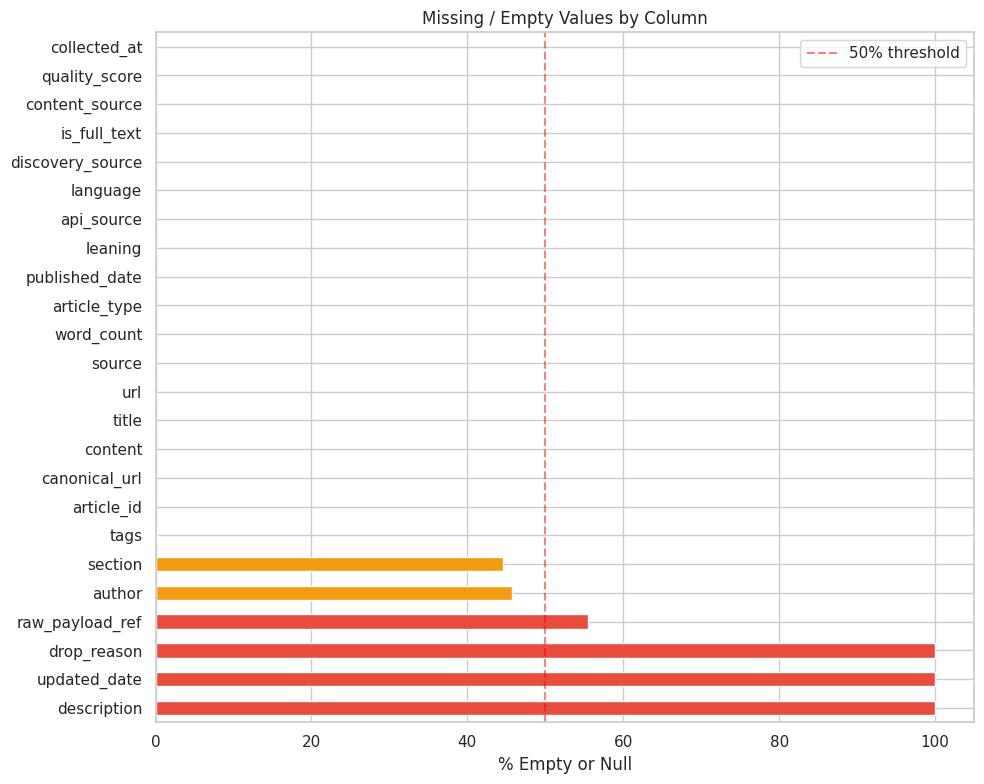


Detailed null/empty counts:
  description                filled=     0  null=10,848  empty=45,438  (100.0% missing)
  updated_date               filled=     0  null=10,848  empty=45,438  (100.0% missing)
  drop_reason                filled=     0  null=10,848  empty=45,438  (100.0% missing)
  raw_payload_ref            filled=25,078  null=     0  empty=31,208  (55.4% missing)
  author                     filled=30,560  null=10,848  empty=14,878  (45.7% missing)
  section                    filled=31,208  null=10,848  empty=14,230  (44.6% missing)
  tags                       filled=56,185  null=     0  empty=   101  (0.2% missing)
  article_id                 filled=56,286  null=     0  empty=     0  (0.0% missing)
  canonical_url              filled=56,286  null=     0  empty=     0  (0.0% missing)
  content                    filled=56,286  null=     0  empty=     0  (0.0% missing)
  title                      filled=56,286  null=     0  empty=     0  (0.0% missing)
  url           

In [4]:
null_pct = (df.isna().sum() + (df == "").sum()) / len(df) * 100
null_pct = null_pct.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
colors = ["#e74c3c" if v > 50 else "#f39c12" if v > 10 else "#2ecc71" for v in null_pct.values]
null_pct.plot(kind="barh", ax=ax, color=colors)
ax.set_xlabel("% Empty or Null")
ax.set_title("Missing / Empty Values by Column")
ax.axvline(x=50, color="red", linestyle="--", alpha=0.5, label="50% threshold")
ax.legend()
plt.tight_layout()
plt.show()

print("\nDetailed null/empty counts:")
for col in null_pct.index:
    na = df[col].isna().sum()
    empty = (df[col] == "").sum() if df[col].dtype == object else 0
    filled = len(df) - na - empty
    print(f"  {col:25s}  filled={filled:>6,}  null={na:>6,}  empty={empty:>6,}  ({null_pct[col]:.1f}% missing)")

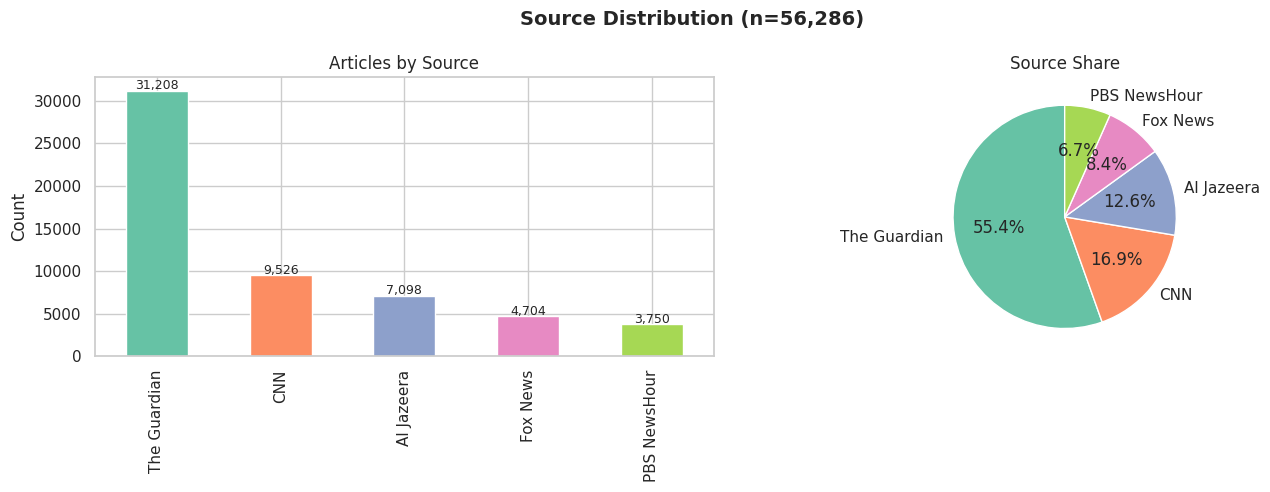

In [5]:
source_counts = df["source"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
source_counts.plot(kind="bar", ax=axes[0], color=sns.color_palette("Set2", len(source_counts)))
axes[0].set_title("Articles by Source")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
for i, (val, name) in enumerate(zip(source_counts.values, source_counts.index)):
    axes[0].text(i, val + 200, f"{val:,}", ha="center", fontsize=9)

# Pie chart
axes[1].pie(source_counts.values, labels=source_counts.index, autopct="%1.1f%%",
            startangle=90, colors=sns.color_palette("Set2", len(source_counts)))
axes[1].set_title("Source Share")

plt.suptitle(f"Source Distribution (n={len(df):,})", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Source → Leaning mapping:
  Al Jazeera           → center
  CNN                  → center-left
  Fox News             → right
  PBS NewsHour         → center
  The Guardian         → center-left


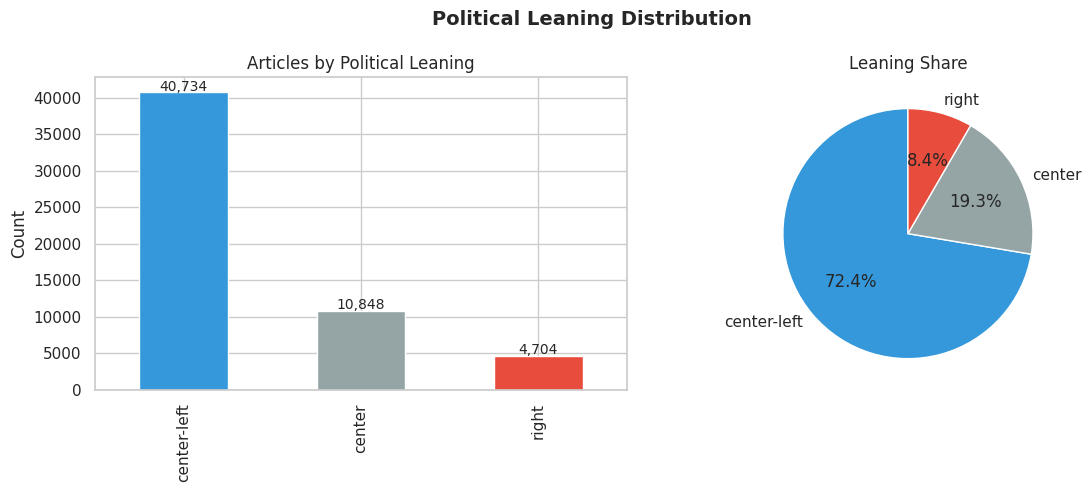


Note: 'leaning' is assigned per-outlet, NOT per-article.
It reflects the outlet's editorial positioning, not individual article bias.


In [6]:
leaning_map = df.groupby("source")["leaning"].first()
print("Source → Leaning mapping:")
for src, lean in leaning_map.items():
    print(f"  {src:20s} → {lean}")

leaning_counts = df["leaning"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

leaning_colors = {"center-left": "#3498db", "center": "#95a5a6", "right": "#e74c3c"}
colors = [leaning_colors.get(l, "#333") for l in leaning_counts.index]

leaning_counts.plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("Articles by Political Leaning")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
for i, v in enumerate(leaning_counts.values):
    axes[0].text(i, v + 200, f"{v:,}", ha="center", fontsize=10)

axes[1].pie(leaning_counts.values, labels=leaning_counts.index, autopct="%1.1f%%",
            colors=colors, startangle=90)
axes[1].set_title("Leaning Share")

plt.suptitle("Political Leaning Distribution", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nNote: 'leaning' is assigned per-outlet, NOT per-article.")
print("It reflects the outlet's editorial positioning, not individual article bias.")

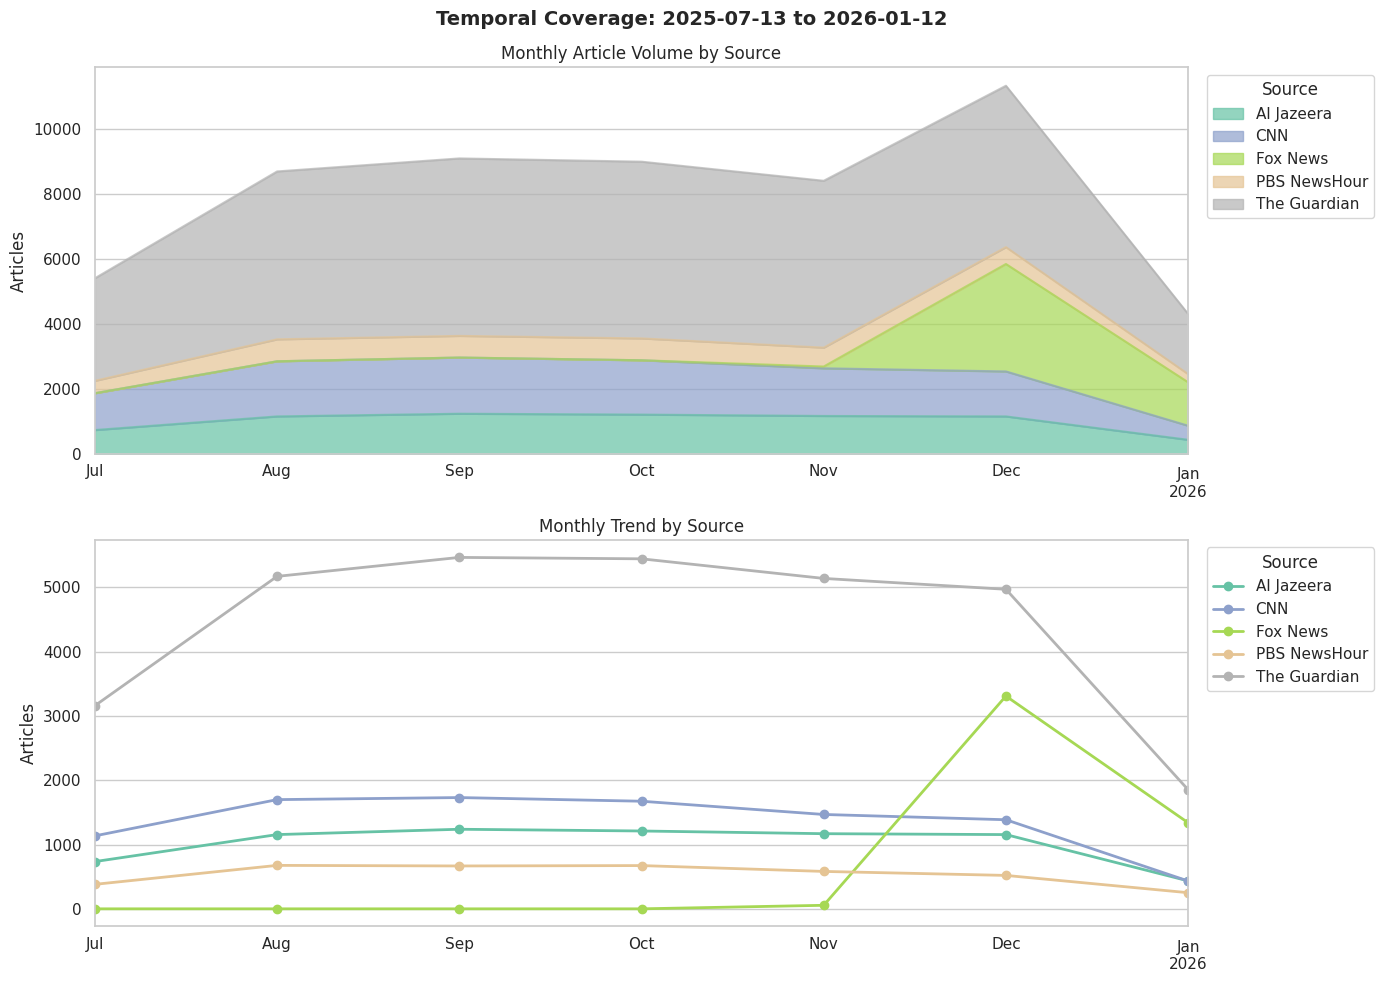


Monthly counts:
source     Al Jazeera   CNN  Fox News  PBS NewsHour  The Guardian
pub_month                                                        
2025-07           735  1135         0           381          3160
2025-08          1155  1699         0           676          5172
2025-09          1238  1731         0           667          5467
2025-10          1211  1674         0           673          5445
2025-11          1169  1468        55           582          5140
2025-12          1155  1386      3310           520          4971
2026-01           435   433      1339           251          1853


In [7]:
df["pub_date"] = pd.to_datetime(df["published_date"], format="mixed", utc=True)
df["pub_month"] = df["pub_date"].dt.to_period("M")

monthly = df.groupby(["pub_month", "source"]).size().unstack(fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Stacked area chart
monthly.plot.area(ax=axes[0], alpha=0.7, colormap="Set2")
axes[0].set_title("Monthly Article Volume by Source")
axes[0].set_ylabel("Articles")
axes[0].set_xlabel("")
axes[0].legend(title="Source", bbox_to_anchor=(1.01, 1), loc="upper left")

# Line chart per source
monthly.plot(ax=axes[1], marker="o", linewidth=2, colormap="Set2")
axes[1].set_title("Monthly Trend by Source")
axes[1].set_ylabel("Articles")
axes[1].set_xlabel("")
axes[1].legend(title="Source", bbox_to_anchor=(1.01, 1), loc="upper left")

plt.suptitle(f"Temporal Coverage: {df['pub_date'].min().strftime('%Y-%m-%d')} to {df['pub_date'].max().strftime('%Y-%m-%d')}",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("\nMonthly counts:")
print(monthly.to_string())

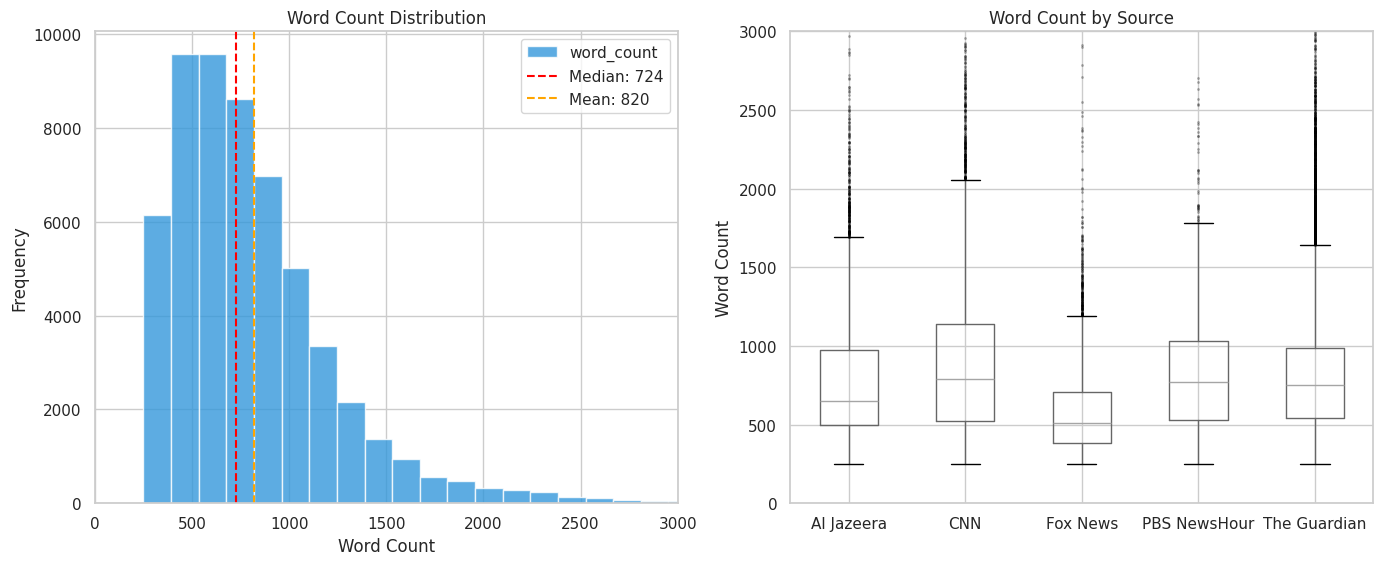

Word Count Statistics by Source:
                count   mean  median    min      max
source                                              
Al Jazeera     7098.0  788.0   653.0  250.0   6062.0
CNN            9526.0  903.0   792.0  250.0   5476.0
Fox News       4704.0  592.0   510.0  250.0   4597.0
PBS NewsHour   3750.0  809.0   770.0  250.0   6728.0
The Guardian  31208.0  838.0   750.0  250.0  11629.0

Overall: min=250, median=724, mean=820, max=11629


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Histogram
df["word_count"].plot(kind="hist", bins=80, ax=axes[0], color="#3498db",
                       edgecolor="white", alpha=0.8)
axes[0].axvline(df["word_count"].median(), color="red", linestyle="--",
                label=f'Median: {df["word_count"].median():.0f}')
axes[0].axvline(df["word_count"].mean(), color="orange", linestyle="--",
                label=f'Mean: {df["word_count"].mean():.0f}')
axes[0].set_title("Word Count Distribution")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")
axes[0].set_xlim(0, 3000)
axes[0].legend()

# Box plot by source
df.boxplot(column="word_count", by="source", ax=axes[1], vert=True,
           flierprops=dict(marker=".", markersize=2, alpha=0.3))
axes[1].set_title("Word Count by Source")
axes[1].set_xlabel("")
axes[1].set_ylabel("Word Count")
axes[1].set_ylim(0, 3000)
plt.suptitle("")

plt.tight_layout()
plt.show()

# Statistics table
print("Word Count Statistics by Source:")
print("=" * 70)
wc_stats = df.groupby("source")["word_count"].describe().round(0)
print(wc_stats[["count", "mean", "50%", "min", "max"]].rename(
    columns={"50%": "median"}).to_string())

print(f"\nOverall: min={df['word_count'].min()}, median={df['word_count'].median():.0f}, "
      f"mean={df['word_count'].mean():.0f}, max={df['word_count'].max()}")

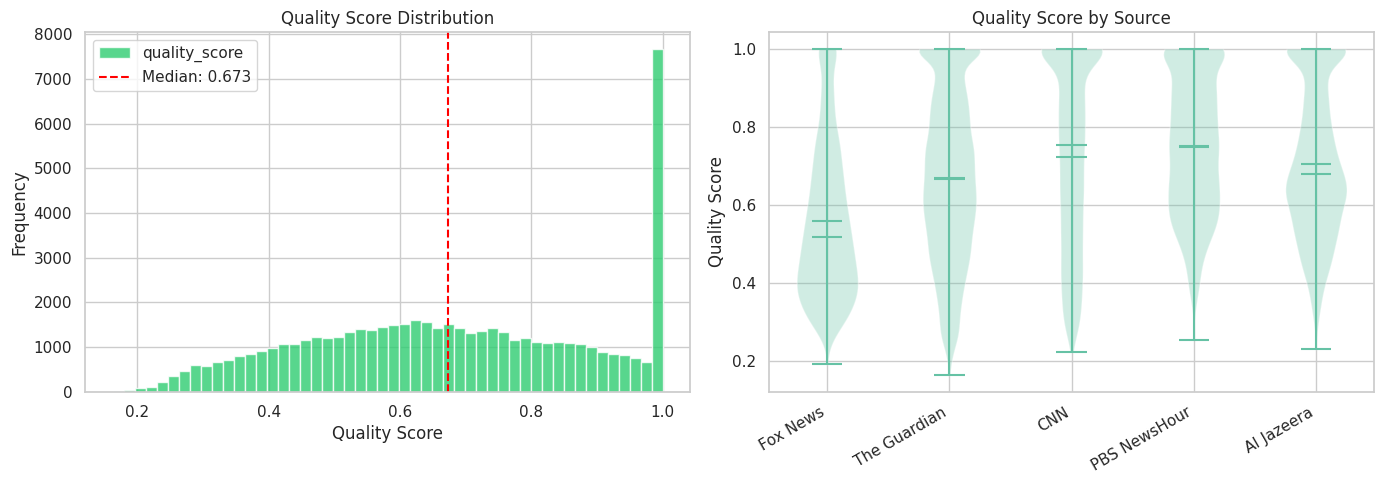

Quality Score Statistics by Source:
                count   mean    std    min    25%    50%    75%  max
source                                                              
Al Jazeera     7098.0  0.705  0.191  0.229  0.561  0.677  0.866  1.0
CNN            9526.0  0.722  0.235  0.222  0.524  0.752  0.963  1.0
Fox News       4704.0  0.557  0.196  0.190  0.400  0.517  0.683  1.0
PBS NewsHour   3750.0  0.748  0.176  0.254  0.607  0.749  0.901  1.0
The Guardian  31208.0  0.669  0.214  0.163  0.507  0.667  0.841  1.0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
df["quality_score"].plot(kind="hist", bins=50, ax=axes[0], color="#2ecc71",
                          edgecolor="white", alpha=0.8)
axes[0].axvline(df["quality_score"].median(), color="red", linestyle="--",
                label=f'Median: {df["quality_score"].median():.3f}')
axes[0].set_title("Quality Score Distribution")
axes[0].set_xlabel("Quality Score")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# Violin plot by source
parts = axes[1].violinplot(
    [df[df["source"] == s]["quality_score"].values for s in df["source"].unique()],
    showmeans=True, showmedians=True
)
axes[1].set_xticks(range(1, len(df["source"].unique()) + 1))
axes[1].set_xticklabels(df["source"].unique(), rotation=30, ha="right")
axes[1].set_title("Quality Score by Source")
axes[1].set_ylabel("Quality Score")

plt.tight_layout()
plt.show()

print("Quality Score Statistics by Source:")
print(df.groupby("source")["quality_score"].describe().round(3).to_string())

Total tag assignments: 299,543
Unique tags: 12,635
Articles with tags: 56,286 / 56,286 (100.0%)


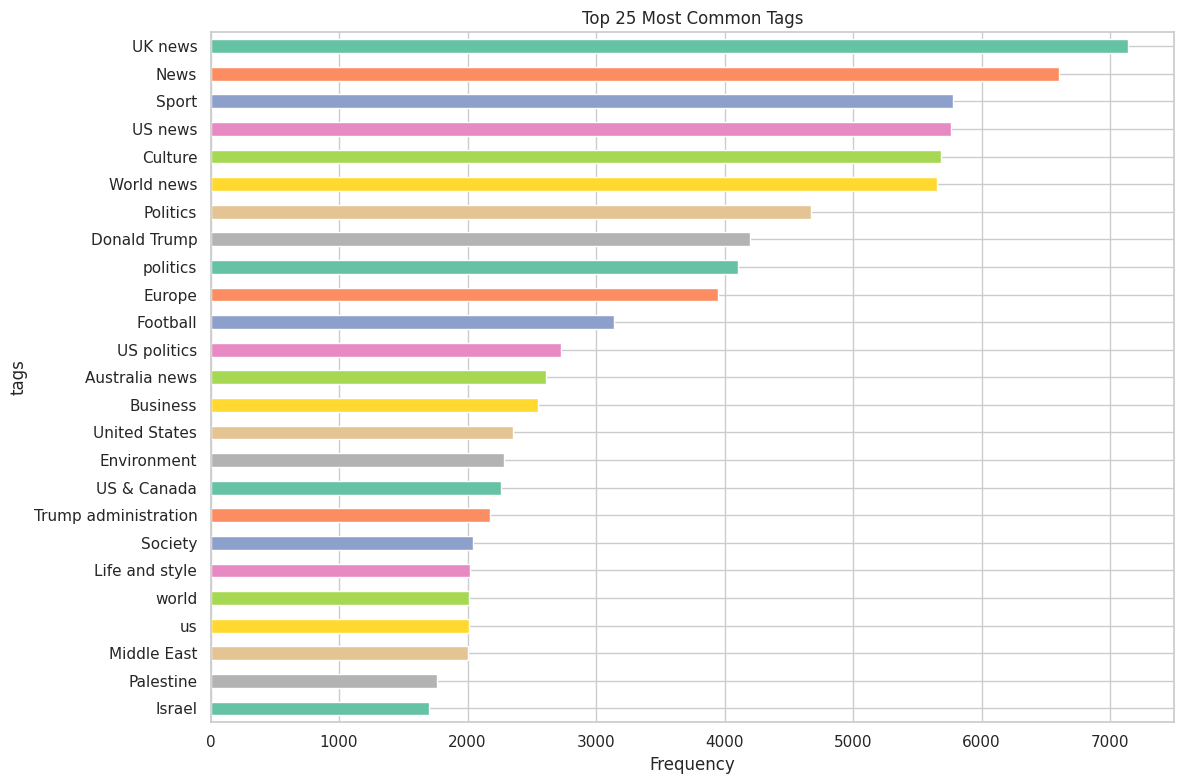


Top 5 tags per source:

Fox News:
  politics: 1473
  donald trump: 896
  sports: 802
  us: 718
  media: 677

The Guardian:
  UK news: 7140
  US news: 5763
  Culture: 5681
  World news: 5653
  Sport: 4993

CNN:
  politics: 2625
  world: 1659
  business: 1355
  us: 1289
  sport: 699

PBS NewsHour:
  donald trump news: 1022
  israel: 289
  gaza: 229
  russia: 228
  ukraine: 183

Al Jazeera:
  News: 6603
  United States: 2354
  US & Canada: 2261
  Middle East: 2001
  Europe: 1855


In [10]:
# Explode tags and count frequencies
tags_series = df["tags"].dropna().str.split(",").explode().str.strip()
tags_series = tags_series[tags_series != ""]
tag_counts = tags_series.value_counts()

print(f"Total tag assignments: {len(tags_series):,}")
print(f"Unique tags: {tag_counts.shape[0]:,}")
print(f"Articles with tags: {df['tags'].notna().sum():,} / {len(df):,} ({df['tags'].notna().mean()*100:.1f}%)")

# Top 25 tags
fig, ax = plt.subplots(figsize=(12, 8))
top_tags = tag_counts.head(25)
top_tags.plot(kind="barh", ax=ax, color=sns.color_palette("Set2", 25))
ax.set_xlabel("Frequency")
ax.set_title("Top 25 Most Common Tags")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Tags per source
print("\nTop 5 tags per source:")
print("=" * 60)
for src in df["source"].unique():
    src_tags = df[df["source"] == src]["tags"].dropna().str.split(",").explode().str.strip()
    src_tags = src_tags[src_tags != ""]
    top5 = src_tags.value_counts().head(5)
    print(f"\n{src}:")
    for tag, count in top5.items():
        print(f"  {tag}: {count}")

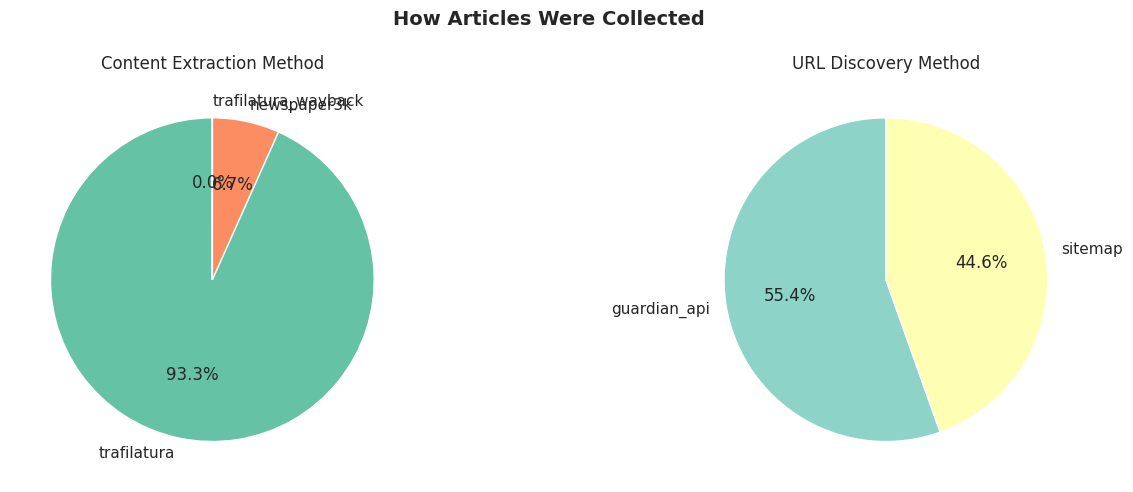

Content extraction breakdown:
  trafilatura: 52,518 (93.3%)
  newspaper3k: 3,766 (6.7%)
  trafilatura_wayback: 2 (0.0%)

Discovery source breakdown:
  guardian_api: 31,208 (55.4%)
  sitemap: 25,078 (44.6%)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Content source
cs = df["content_source"].value_counts()
axes[0].pie(cs.values, labels=cs.index, autopct="%1.1f%%",
            colors=sns.color_palette("Set2", len(cs)), startangle=90)
axes[0].set_title("Content Extraction Method")

# Discovery source
ds = df["discovery_source"].value_counts()
axes[1].pie(ds.values, labels=ds.index, autopct="%1.1f%%",
            colors=sns.color_palette("Set3", len(ds)), startangle=90)
axes[1].set_title("URL Discovery Method")

plt.suptitle("How Articles Were Collected", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print("Content extraction breakdown:")
for method, count in cs.items():
    print(f"  {method}: {count:,} ({count/len(df)*100:.1f}%)")

print(f"\nDiscovery source breakdown:")
for method, count in ds.items():
    print(f"  {method}: {count:,} ({count/len(df)*100:.1f}%)")

In [12]:
print("=" * 80)
print("SAMPLE ARTICLES (1 per source)")
print("=" * 80)

for source in df["source"].unique():
    row = df[df["source"] == source].sample(1, random_state=42).iloc[0]
    print(f"\n{'─' * 80}")
    print(f"SOURCE:    {row['source']} ({row['leaning']})")
    print(f"TITLE:     {row['title']}")
    print(f"DATE:      {row['published_date']}")
    print(f"WORDS:     {row['word_count']}")
    print(f"TAGS:      {str(row['tags'])[:120]}")
    print(f"QUALITY:   {row['quality_score']:.3f}")
    print(f"CONTENT:   {row['content'][:300]}...")

SAMPLE ARTICLES (1 per source)

────────────────────────────────────────────────────────────────────────────────
SOURCE:    Fox News (right)
TITLE:     Company restores AI teddy bear sales after safety scare
DATE:      2025-12-01T06:17:06-05:00
WORDS:     1167
TAGS:      artificial intelligence, toys, technologies, tech
QUALITY:   0.981
CONTENT:   FoloToy paused sales of its AI teddy bear Kumma after a safety group found the toy gave risky and inappropriate responses during testing. Now the company says it has restored sales after a week of intense review. It also claims that it improved safeguards to keep kids safe.
The announcement arrived ...

────────────────────────────────────────────────────────────────────────────────
SOURCE:    The Guardian (center-left)
TITLE:     New book details infighting behind Trump’s ‘obviously unqualified’ cabinet picks 
DATE:      2025-10-23T14:30:42+00:00
WORDS:     815
TAGS:      Trump administration, Republicans, Donald Trump, US politics, Books, U